<a href="https://colab.research.google.com/github/erickcorrea3092/Antimalaria_QSAR/blob/main/2_B%C3%BAsqueda_olaf_E.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Antecedentes

## Imports

In [17]:
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import KFold, StratifiedShuffleSplit
from sklearn.svm import SVR
from sklearn.svm import NuSVR
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, StratifiedShuffleSplit
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer
from sklearn.feature_selection import (SelectFromModel, SelectKBest,
                                       VarianceThreshold)

## Globales

In [18]:
# 1 semilla para cosas random
RANDOM_STATE = 5712492

# 2 Minima varianza a conservar en las features
MIN_VARIANCE = 0

# 3 Separación
N_BINS= 5 ##discretizer
N_SPLITS= 4 ##splitter
TEST_SIZE= 20/63 ##splitter

# 4 Algoritmo de escalamiento

# Otros que se pueden utilizar:StandardScaler(), MinMaxScaler() o Normalizer()
SCALER = StandardScaler()

# 5 Primer selector/transformador de features
feat_selector_model = RandomForestRegressor(
    #  n_estimators=40,min_samples_leaf=3,
     random_state=RANDOM_STATE,
    #                                         min_samples_split=6,max_features=0.3,criterion='squared_error',
    #                                         max_depth=None,min_weight_fraction_leaf = 0.0
                                            )
FEAT_SELECTOR1 = SelectFromModel(feat_selector_model, max_features=16)

# 6 Segundo selector/transformador de features
n_pca = 9
FEAT_SELECTOR2 = PCA(n_components=n_pca, random_state=RANDOM_STATE)

# 7 Algoritmo de regresión
REGRESSOR = SVR(#C=1, #epsilon = 0.2
                )

# 8 Validación cruzada
METRICS = ["r2", "neg_mean_squared_error"]
CV_SPLITTER = KFold(n_splits=7, shuffle=True, random_state=RANDOM_STATE)



## Datos


In [19]:
# descargamos data
! gdown --id 1Kj0pbo_WR0LZDnMqlVfnU7rTPBGYqsV8 ##Descriptores


/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1Kj0pbo_WR0LZDnMqlVfnU7rTPBGYqsV8
To: /content/descriptors.xlsx
100% 1.09M/1.09M [00:00<00:00, 18.2MB/s]


In [20]:
#Guardamos la data como una nueva variable
data = pd.read_excel("descriptors.xlsx")
df_y = data["Activity"] #Esta es opcional opción 2

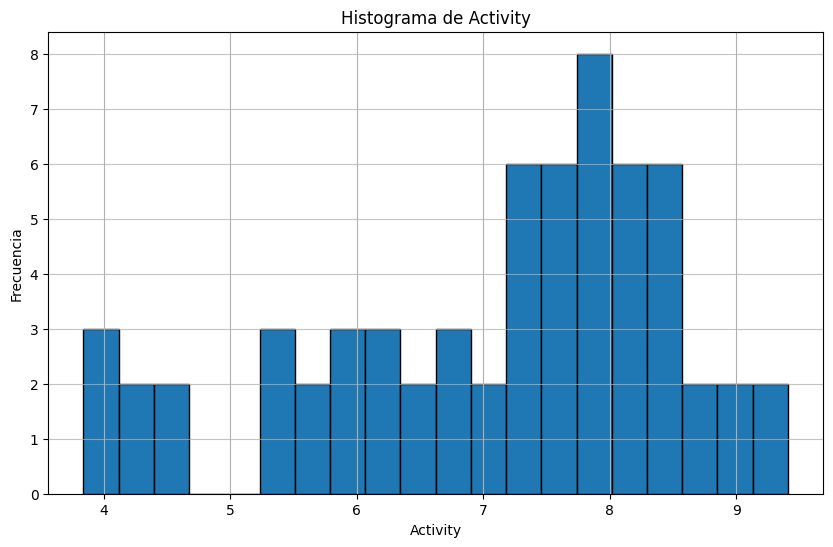

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
df_y.hist (bins=20, edgecolor='black',)
plt.title('Histograma de Activity')
plt.xlabel('Activity')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.75)
plt.show()

In [22]:
# Importamos datos
#_____________________________________________
df_x = data.copy()
df_x = df_x.drop('Activity', axis=1) # Este renglón puede ser útil #Opción 2
df_x = df_x.select_dtypes("number")  # quitar non_numeric
#_____________________________________________
df_data = df_x.assign(Activity=df_y)
df_x

,ABC,ABCGG,nAcid,nBase,nAromAtom,nAromBond,nAtom,nHeavyAtom,nSpiro,nBridgehead,...,SRW09,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb2
0,16.444395,13.117993,0,0,0,0,42,20,1,2,...,6.111467,10.555735,64.859213,282.146724,6.717779,627,48,122,156,4.083333
1,15.797149,14.045829,0,0,0,0,42,20,1,0,...,6.898715,10.362967,68.755678,282.146724,6.717779,677,39,112,140,4.291667
2,15.737288,12.888316,0,0,0,0,41,19,1,2,...,7.412764,10.564499,69.143759,266.151809,6.491508,549,42,118,152,3.833333
3,16.492175,13.580210,0,0,0,0,42,20,1,2,...,7.434257,10.637225,70.456546,282.146724,6.717779,630,46,124,161,4.041667
4,16.444395,13.117993,0,0,0,0,40,20,1,2,...,6.111467,10.555735,64.859213,280.131074,7.003277,627,48,122,156,4.083333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,23.322593,16.977055,0,0,16,17,57,30,0,0,...,0.000000,10.206440,65.460570,401.210327,7.038778,2687,45,154,178,6.750000
59,24.098650,17.217972,0,0,16,17,49,30,0,0,...,7.379632,10.321836,81.650049,423.126948,8.635244,2992,45,164,194,6.444444
60,24.805756,17.513788,0,0,16,17,52,31,0,0,...,7.379632,10.329768,82.737892,437.142598,8.406588,3380,46,168,198,6.694444
61,17.775129,13.806503,0,1,16,17,44,23,0,0,...,0.000000,10.004735,57.248190,307.168462,6.981101,1286,35,118,137,5.166667


## Load data

In [23]:
# Cargamos data
df_x = df_x.select_dtypes("number")  # quitar non_numeric
# Agregamos columna de actividad biológica
df_data = df_x.assign(Activity=df_y)
df_data

,ABC,ABCGG,nAcid,nBase,nAromAtom,nAromBond,nAtom,nHeavyAtom,nSpiro,nBridgehead,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb2,Activity
0,16.444395,13.117993,0,0,0,0,42,20,1,2,...,10.555735,64.859213,282.146724,6.717779,627,48,122,156,4.083333,7.982967
1,15.797149,14.045829,0,0,0,0,42,20,1,0,...,10.362967,68.755678,282.146724,6.717779,677,39,112,140,4.291667,7.031657
2,15.737288,12.888316,0,0,0,0,41,19,1,2,...,10.564499,69.143759,266.151809,6.491508,549,42,118,152,3.833333,3.840162
3,16.492175,13.580210,0,0,0,0,42,20,1,2,...,10.637225,70.456546,282.146724,6.717779,630,46,124,161,4.041667,4.625068
4,16.444395,13.117993,0,0,0,0,40,20,1,2,...,10.555735,64.859213,280.131074,7.003277,627,48,122,156,4.083333,7.522879
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,23.322593,16.977055,0,0,16,17,57,30,0,0,...,10.206440,65.460570,401.210327,7.038778,2687,45,154,178,6.750000,5.853872
59,24.098650,17.217972,0,0,16,17,49,30,0,0,...,10.321836,81.650049,423.126948,8.635244,2992,45,164,194,6.444444,5.381952
60,24.805756,17.513788,0,0,16,17,52,31,0,0,...,10.329768,82.737892,437.142598,8.406588,3380,46,168,198,6.694444,5.384050
61,17.775129,13.806503,0,1,16,17,44,23,0,0,...,10.004735,57.248190,307.168462,6.981101,1286,35,118,137,5.166667,6.638272


In [24]:
TEST_SIZE*63

20.0

In [25]:
TEST_SIZE

0.31746031746031744

In [26]:
# dividimos train test con stratified
discretizer = sklearn.preprocessing.KBinsDiscretizer(n_bins=N_BINS, encode="ordinal", strategy="uniform")
splitter = StratifiedShuffleSplit(n_splits=N_SPLITS, test_size=TEST_SIZE, random_state=RANDOM_STATE)
# Reshape y_discrete to be a 2D array (n_samples, 1)
y_discrete = discretizer.fit_transform(df_y.values.reshape(-1, 1))
split, split_test = next(splitter.split(df_x.values, y_discrete))
fractions = ["train" if i in split else "test" for i in range(df_data.shape[0])]
df_data = df_data.assign(fraction=fractions)
df_data

,ABC,ABCGG,nAcid,nBase,nAromAtom,nAromBond,nAtom,nHeavyAtom,nSpiro,nBridgehead,...,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb2,Activity,fraction
0,16.444395,13.117993,0,0,0,0,42,20,1,2,...,64.859213,282.146724,6.717779,627,48,122,156,4.083333,7.982967,train
1,15.797149,14.045829,0,0,0,0,42,20,1,0,...,68.755678,282.146724,6.717779,677,39,112,140,4.291667,7.031657,test
2,15.737288,12.888316,0,0,0,0,41,19,1,2,...,69.143759,266.151809,6.491508,549,42,118,152,3.833333,3.840162,train
3,16.492175,13.580210,0,0,0,0,42,20,1,2,...,70.456546,282.146724,6.717779,630,46,124,161,4.041667,4.625068,train
4,16.444395,13.117993,0,0,0,0,40,20,1,2,...,64.859213,280.131074,7.003277,627,48,122,156,4.083333,7.522879,test
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,23.322593,16.977055,0,0,16,17,57,30,0,0,...,65.460570,401.210327,7.038778,2687,45,154,178,6.750000,5.853872,test
59,24.098650,17.217972,0,0,16,17,49,30,0,0,...,81.650049,423.126948,8.635244,2992,45,164,194,6.444444,5.381952,train
60,24.805756,17.513788,0,0,16,17,52,31,0,0,...,82.737892,437.142598,8.406588,3380,46,168,198,6.694444,5.384050,train
61,17.775129,13.806503,0,1,16,17,44,23,0,0,...,57.248190,307.168462,6.981101,1286,35,118,137,5.166667,6.638272,train


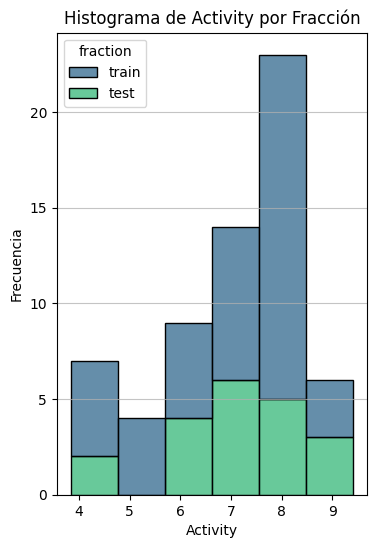

In [27]:
import seaborn as sns

plt.figure(figsize=(4, 6))
sns.histplot(data=df_data, x='Activity', hue='fraction', multiple='stack', bins=6, palette='viridis')
plt.title('Histograma de Activity por Fracción')
plt.xlabel('Activity')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.75)
plt.show()

In [28]:
# sacamos los vectores (x, y) de interés
x_train = df_x[df_data["fraction"] == "train"].values
y_train = df_y[df_data["fraction"] == "train"].values
x_test = df_x[df_data["fraction"] == "test"].values
y_test = df_y[df_data["fraction"] == "test"].values
y_train = np.reshape(y_train, -1)
y_test = np.reshape(y_test, -1)

x_train = x_train.astype(float)
y_train = y_train.astype(float)
x_test = x_test.astype(float)
y_test = y_test.astype(float)

# x_train





# Train & Evaluate

In [29]:
# creamos pipeline: el modelo final final
steps = [
    ("var0", VarianceThreshold(MIN_VARIANCE)),
    ("scaling", SCALER),
    ("feat_selector1", FEAT_SELECTOR1),
    ("feat_selector2", FEAT_SELECTOR2),
    ("regressor", REGRESSOR)
]
pipeline = Pipeline(steps, verbose=True)
pipeline = pipeline.fit(x_train, y_train)
pipeline.set_params(verbose=False)
pipeline

[Pipeline] .............. (step 1 of 5) Processing var0, total=   0.0s
[Pipeline] ........... (step 2 of 5) Processing scaling, total=   0.0s
[Pipeline] .... (step 3 of 5) Processing feat_selector1, total=   1.8s
[Pipeline] .... (step 4 of 5) Processing feat_selector2, total=   0.0s
[Pipeline] ......... (step 5 of 5) Processing regressor, total=   0.0s


Pipeline(steps=[('var0', VarianceThreshold(threshold=0)),
                ('scaling', StandardScaler()),
                ('feat_selector1',
                 SelectFromModel(estimator=RandomForestRegressor(random_state=5712492),
                                 max_features=16)),
                ('feat_selector2', PCA(n_components=9, random_state=5712492)),
                ('regressor', SVR())])

In [30]:
# analizamos paso a paso las transformaciones
z = x_train
for (i, step) in enumerate(pipeline[:-1]):
    print(f"Step {pipeline.steps[i][0]} ({i}): {step.__class__.__name__}")
    print(f"  Input: {z.shape}. Output: {step.transform(z).shape}")
    z = step.transform(z)

Step var0 (0): VarianceThreshold
  Input: (43, 1122). Output: (43, 922)
Step scaling (1): StandardScaler
  Input: (43, 922). Output: (43, 922)
Step feat_selector1 (2): SelectFromModel
  Input: (43, 922). Output: (43, 16)
Step feat_selector2 (3): PCA
  Input: (43, 16). Output: (43, 9)


# resultados


In [31]:
# validar accuracy
metric = "r2"
# cv = sklearn.model_selection.LeaveOneOut()
cv = sklearn.model_selection.KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
cv_scores = sklearn.model_selection.cross_val_score(pipeline, x_train, y_train, cv=cv, verbose=2, scoring=metric)
scorer = sklearn.metrics.get_scorer(metric)
pd.DataFrame([{"train": scorer(pipeline, x_train, y_train),
               "cv": np.mean(cv_scores),
               "test": scorer(pipeline, x_test, y_test),
               "metric": metric}])

[CV] END .................................................... total time=   1.7s
[CV] END .................................................... total time=   1.4s
[CV] END .................................................... total time=   1.1s
[CV] END .................................................... total time=   1.2s


[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    5.4s finished


,train,cv,test,metric
0,0.642566,0.126672,0.242165,r2


In [32]:
# from sklearn.model_selection import GridSearchCV

# # Definimos el diccionario de parámetros a buscar
# # Usamos la sintaxis 'nombre_paso__nombre_parametro'
# param_grid = {
#     'feat_selector1__max_features': [5, 10, 13, 20],
#     'feat_selector2__n_components': [3, 5, 8, 10],
#     'regressor__C': [0.1, 1, 10, 100],
#     'regressor__epsilon': [0.01, 0.05, 0.1, 0.2]
# }

# # Creamos el objeto GridSearchCV utilizando la métrica r2 y el splitter de validación cruzada
# grid_search = GridSearchCV(
#     estimator=pipeline,
#     param_grid=param_grid,
#     scoring='r2',
#     cv=cv,
#     n_jobs=-1,
#     verbose=1
# )

# # Ejecutamos la búsqueda con los datos de entrenamiento
# grid_search.fit(x_train, y_train)

# # Mostramos los resultados
# print("=== MEJORES HIPERPARÁMETROS ENCONTRADOS ===")
# print(grid_search.best_params_)
# print(f"Mejor score R2 en CV: {grid_search.best_score_:.4f}")

# # Evaluamos el mejor modelo en el conjunto de prueba
# best_model = grid_search.best_estimator_
# test_score = best_model.score(x_test, y_test)
# print(f"R2 en el conjunto de Test con el mejor modelo: {test_score:.4f}")

# # Resumen del comportamiento de las mejores combinaciones
# results_df = pd.DataFrame(grid_search.cv_results_)
# results_df = results_df.sort_values(by='rank_test_score')

# print("\n=== RESUMEN DE LAS MEJORES 5 COMBINACIONES ===")
# print(results_df[['params', 'mean_test_score', 'std_test_score']].head(5).to_string(max_colwidth=100))